In [1]:
import numpy as np
import matplotlib.pyplot as plt
params = {'legend.fontsize': 'large',
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large',
         'xtick.direction':'in',
         'ytick.direction':'in',
         }
plt.rcParams.update(params)

# 偏微分方程式

偏微分方程式は、たとえば**場**などの複数変数の関数を扱うときに出てくる。

例としては：

- 静電ポテンシャル $\phi (x,y,z)$ (Poisson's equation)
$$
\Delta\phi(x,y,z) = -\frac{\rho(x,y,z)}{\epsilon_0}
$$

- 密度/温度分布 (拡散/熱伝導 equation)
$$
\frac{\partial u(\mathbf{x},t)}{\partial t} = D \Delta u(\mathbf{x},t)
$$

- 変位 (振幅) 分布 (波動方程式)
$$
\frac{\partial^2 u(\mathbf{x},t)}{\partial t^2} = c^2\Delta u(\mathbf{x},t)
$$

- 流体方程式 (流速) -- e.g. Navier-Stokes 方程式
$$
\frac{\partial \boldsymbol{u}}{\partial t} + (\boldsymbol{u} \cdot \boldsymbol{\nabla}) \boldsymbol{u} = - \frac1{\rho} \boldsymbol{\nabla} p + \nu \nabla^2 \boldsymbol{u} + \boldsymbol{g}
$$

### 偏微分方程式の一般的解法

- **有限差分法**
    - 微分を有限差分で近似
    - 他の方法より簡単に実装可能
    - 通常の形状（長方形など）に最適
- 有限要素法
    - システムを小さな部分に分割する
    - 2次元/3次元の境界値問題
    - 不規則な形状にも有効
- 有限体積法
    - 各メッシュポイントの周囲の面積分を体積積分に変換
    - 設計上、質量が保存されるため、流体方程式に適する

# 境界値問題

静電ポテンシャルの例として、正方形領域のラプラス方程式を考える。
上辺の角を除いた点を電位 V、ほかの境界点を 0 とする。以下のNotebookでは、
この条件を数値的に解いて電位分布を可視化する。

Source: M. Newman, Computational Physics


## Jacobi 法 (緩和法)

初期推定値$\phi_0(x,y)$から始める。箱内の全ての点$(x,y)$について次の反復は次のように与えられる。
$$
\phi_{n+1}(x,y) = \frac{\phi_n(x+a,y) + \phi_n(x-a,y) + \phi_n(x,y+a) + \phi_n(x,y-a)}{4}
$$
各反復において境界条件は保存される：
\begin{align*}
\phi_{n+1}(x,L) & = V, \\
\phi_{n+1}(x,0) & = 0, \\
\phi_{n+1}(0,y) & = 0, \\
\phi_{n+1}(L,y) & = 0.
\end{align*}

これはヤコビ法（または緩和法）であり、ラプラス方程式では常に収束することが知られる。

In [2]:
# Jacobi法の1ステップ。境界条件は固定する。
def laplace_residual(phi):
    return (phi[2:, 1:-1] + phi[:-2, 1:-1]
            + phi[1:-1, 2:] + phi[1:-1, :-2]
            - 4 * phi[1:-1, 1:-1])

def iteration_jacobi(phinew, phi):
    phinew[...] = phi
    phinew[1:-1, 1:-1] = 0.25 * (
        phi[2:, 1:-1] + phi[:-2, 1:-1]
        + phi[1:-1, 2:] + phi[1:-1, :-2]
    )
    return np.max(np.abs(phinew - phi))

def jacobi_solve(phi0, target_accuracy=1e-6, max_iterations=20_000):
    old = phi0.copy()
    new = np.empty_like(old)
    for iteration in range(1, max_iterations + 1):
        delta = iteration_jacobi(new, old)
        old, new = new, old
        if delta <= target_accuracy:
            print(f"Jacobi method converged in {iteration} iterations")
            return old
    raise RuntimeError(f"Jacobi did not converge; last update={delta:g}")


Jacobi method converged in 1564 iterations
maximum discrete residual: 3.9983090043604896e-05


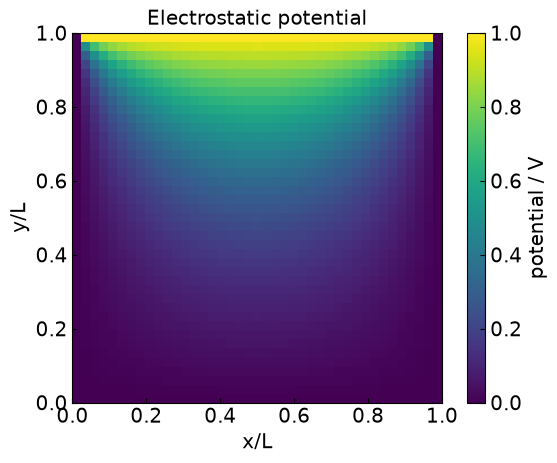

CPU times: user 120 ms, sys: 6.07 ms, total: 126 ms
Wall time: 125 ms


In [3]:
%%time

M = 40
V = 1.0
target = 1e-5
phi = np.zeros((M + 1, M + 1), dtype=float)
phi[1:-1, -1] = V

phi = jacobi_solve(phi, target, 20_000)
residual = np.max(np.abs(laplace_residual(phi)))
assert residual < 1e-3
assert np.all(phi >= -1e-12) and np.all(phi <= V + 1e-12)
print("maximum discrete residual:", residual)

plt.figure()
plt.title("Electrostatic potential")
plt.xlabel("x/L")
plt.ylabel("y/L")
image = plt.imshow(phi.T, vmin=0, vmax=V, origin="lower", extent=[0, 1, 0, 1])
plt.colorbar(image, label="potential / V")
plt.gca().set_aspect("equal")
plt.show()


## Gauss--Seidel法とSOR法

Gauss--Seidel法では、計算済みの近傍値を同じ反復の中で使う。
SOR法はGauss--Seidel更新値を \(\bar\phi_{i,j}^{GS}\) と書くと、
\[
\phi_{i,j}^{new}=\phi_{i,j}^{old}
+\omega\left(\bar\phi_{i,j}^{GS}-\phi_{i,j}^{old}\right),
\qquad 0<\omega<2.
\]
\(\omega=1\) はGauss--Seidel法、\(1<\omega<2\) は過緩和にあたる。
2次元ラプラス方程式では、この範囲でSOR法が収束する。


In [4]:
# Gauss-Seidel法とSOR法。omega=1はGauss-Seidel法に一致する。
def sor_iteration(phi, omega=1.0):
    M = len(phi) - 1
    delta = 0.0
    for i in range(1, M):
        for j in range(1, M):
            old = phi[i, j]
            average = 0.25 * (
                phi[i - 1, j] + phi[i + 1, j]
                + phi[i, j - 1] + phi[i, j + 1]
            )
            phi[i, j] = old + omega * (average - old)
            delta = max(delta, abs(phi[i, j] - old))
    return delta

def sor_solve(phi0, omega=1.0, target_accuracy=1e-6, max_iterations=10_000):
    phi = phi0.copy()
    for iteration in range(1, max_iterations + 1):
        delta = sor_iteration(phi, omega)
        if delta <= target_accuracy:
            print(f"SOR method converged in {iteration} iterations")
            return phi
    raise RuntimeError(f"SOR did not converge; last update={delta:g}")


SOR method converged in 212 iterations
maximum discrete residual: 3.5974209030564808e-06


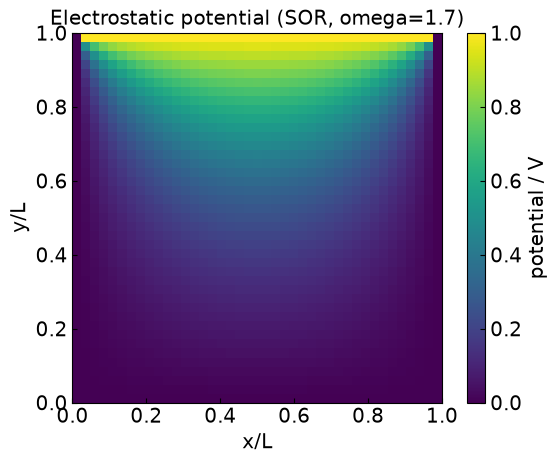

CPU times: user 296 ms, sys: 5.03 ms, total: 301 ms
Wall time: 300 ms


In [5]:
%%time

M = 40
V = 1.0
target = 1e-5
phi = np.zeros((M + 1, M + 1), dtype=float)
phi[1:-1, -1] = V

omega = 1.7
phi = sor_solve(phi, omega, target, 10_000)
residual = np.max(np.abs(laplace_residual(phi)))
assert residual < 1e-3
print("maximum discrete residual:", residual)

plt.figure()
plt.title(f"Electrostatic potential (SOR, omega={omega})")
plt.xlabel("x/L")
plt.ylabel("y/L")
image = plt.imshow(phi.T, vmin=0, vmax=V, origin="lower", extent=[0, 1, 0, 1])
plt.colorbar(image, label="potential / V")
plt.gca().set_aspect("equal")
plt.show()


一般に、SOR 法の方が、収束が早く、必要なステップ数が少ないことが確認できるだろう。

# 初期値問題

ほとんどの場合、物理ではある分布関数 $u(t,\mathbf{x})$ の時間発展に興味がある。
この場合、偏微分方程式は、いくつかの初期条件から始まり境界条件に従う、場の時間発展を記述する。

例として熱方程式を取り上げる。
場 $u$ は温度 $T$ である。
1次元の場合、熱方程式は次のように表される。
$$
\frac{\partial u}{\partial t} = D \, \frac{\partial^2 u}{\partial x^2},
$$
ここで、$D$ は熱拡散率定数。

この式は、初期分布が与えられた場合の$u(t,x)$の時間発展を記述する。初期分布は
$$
u(t=0,x) = u_0(x)、
$$
および境界条件は
\begin{align*}
u(t,x=0) & = u_{\rm left}(t)、\\
u(t,x=L) & = u_{\rm right}(t)。
\end{align*}

$u_{\rm left}(t)$と$u_{\rm right}(t)$が時間に依存しない場合、解は$t \to \infty$のときに定常解に近づく。

## 1. FTCS 法

FTCS (Forward Time Centered Space) 法は熱伝導方程式を解く最も簡単な方法である。

まず、空間座標を$N + 1$点のグリッドに離散化する。つまり、
$$
x_k = a k, \qquad k = 0\ldots N, \qquad a = L/N,
$$
そして、微分 $\partial^2 u / \partial x^2$ を最低次の中心差分で近似する。
$$
\frac{\partial^2 u(t,x)}{\partial x^2} \approx \frac{u(t,x+a) - 2u(t,x) + u(t,x-a)}{a^2}.
$$

時間発展を評価するために、時刻をサイズ $h$ の幅に刻む。
時間微分は前進差分で近似される。
$$
\frac{\partial u(t,x)}{\partial t} \approx \frac{u(t+h,x) - u(t,x)}{h}.
$$

これにより、次の離散化方程式が得られる。
$$
\frac{u(t+h,x) - u(t,x)}{h} = D \frac{u(t,x+a) - 2u(t,x) + u(t,x-a)}{a^2}.
$$
この方法は陽解法である。次の時間ステップにおける $u(t+h,x)$ を評価するには、現在の時間ステップにおける $u(t,x)$ のみが必要になる。
離散化された時間変数を上付き文字 $n$（$t_n = hn$）で表し、空間変数を下付き文字 $k$（$x_k = ak$）で表すと、次の反復が得られる。
$$
u^{n+1}_k = u^n_k + r \, (u^n_{k+1} - 2u^n_k + u^n_{k-1}), \qquad k = 1 \ldots N-1.
$$
ここで
$$
r \equiv \frac{Dh}{a^2}
$$
は無次元パラメータ。

In [6]:
# 熱方程式FTCS法の1ステップ。境界値は固定する。
def heat_FTCS_iteration(u, r):
    unew = u.copy()
    unew[1:-1] = u[1:-1] + r * (u[2:] - 2 * u[1:-1] + u[:-2])
    return unew

def heat_FTCS_solve(u0, h, nsteps, a, D=1.0):
    u = u0.copy()
    r = h * D / a**2
    for _ in range(nsteps):
        u = heat_FTCS_iteration(u, r)
    return u


今、長さ1 cm、初期温度20&deg; Cのステンレスの棒を考える。
この容器の左端は50&deg; Cの温水浴槽に接し、右端は0&deg; Cの冷水浴槽に接する。
このとき、温度分布を $t = 0.01$ s, $0.1$ s, $0.4$ s, $1$ s, $10$ s で計算せよ。
ただし、ステンレスの熱拡散率は $D = 4.25 \cdot 10^{-6} \mathrm{m}^2 \mathrm{s}^{-1}$ とする。

Solving the heat equation with FTCS; r = 0.4


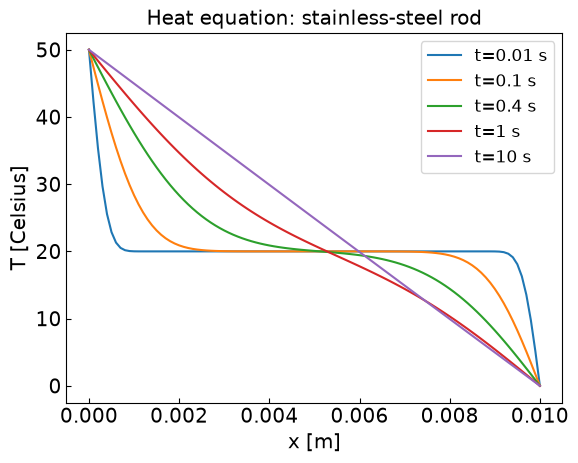

CPU times: user 235 ms, sys: 2.11 ms, total: 237 ms
Wall time: 236 ms


In [7]:
%%time

L = 0.01
D = 4.25e-6
N = 100
a = L / N
h = 0.4 * a**2 / D
r = h * D / a**2
print("Solving the heat equation with FTCS; r =", r)

Tlo, Tmid, Thi = 0.0, 20.0, 50.0
u = np.full(N + 1, Tmid, dtype=float)
u[0], u[-1] = Thi, Tlo

times = [0.01, 0.1, 0.4, 1.0, 10.0]
profiles = []
xk = np.linspace(0, L, N + 1)
current_time = 0.0
for time in times:
    nsteps = round((time - current_time) / h)
    u = heat_FTCS_solve(u, h, nsteps, a, D)
    profiles.append(u.copy())
    current_time += nsteps * h

plt.figure()
plt.title("Heat equation: stainless-steel rod")
plt.xlabel("x [m]")
plt.ylabel("T [Celsius]")
for time, profile in zip(times, profiles):
    plt.plot(xk, profile, label=f"t={time:g} s")
plt.legend()
plt.show()


FTCSの安定条件を破ると高周波成分が増幅する。次のセルでは
r=0.6の意図的に不安定な設定を8ステップだけ計算する。
境界値から独立した小さな交互振動を使い、有限値の範囲で増幅を観察する。


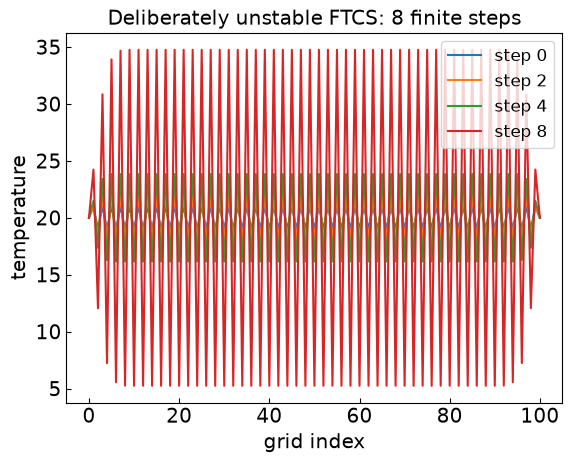

CPU times: user 74.4 ms, sys: 4.03 ms, total: 78.5 ms
Wall time: 77.7 ms


In [8]:
%%time

N = 100
r = 0.6
x = np.linspace(0, 1, N + 1)
u = np.full(N + 1, 20.0)
u[1:-1] += (-1.0) ** np.arange(N - 1)
profiles = [u.copy()]
for _ in range(8):
    u = heat_FTCS_iteration(u, r)
    profiles.append(u.copy())

assert np.isfinite(profiles).all()
assert np.max(np.abs(profiles[-1] - 20.0)) > 5
plt.figure()
plt.title("Deliberately unstable FTCS: 8 finite steps")
plt.xlabel("grid index")
plt.ylabel("temperature")
for step in (0, 2, 4, 8):
    plt.plot(profiles[step], label=f"step {step}")
plt.legend()
plt.show()


$r<1/2$ となるように、空間のステップサイズを変えたらどうなるか？

Solving the heat equation with FTCS; r = 0.41309999999999986


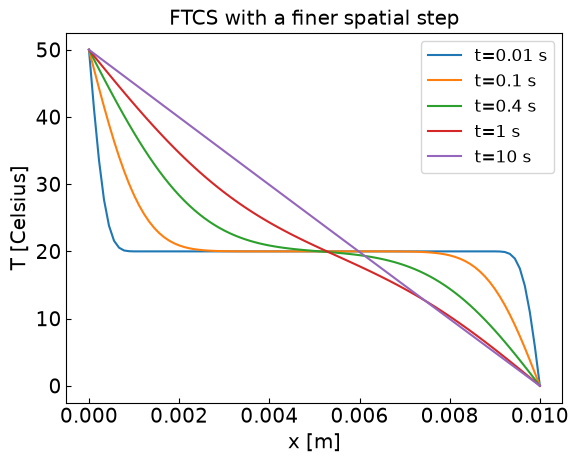

CPU times: user 78.8 ms, sys: 967 μs, total: 79.8 ms
Wall time: 78.9 ms


In [9]:
%%time

L = 0.01
D = 4.25e-6
N = 90
a = L / N
h = 1.2e-3
r = h * D / a**2
print("Solving the heat equation with FTCS; r =", r)
assert r < 0.5

u = np.full(N + 1, 20.0)
u[0], u[-1] = 50.0, 0.0
times = [0.01, 0.1, 0.4, 1.0, 10.0]
profiles = []
xk = np.linspace(0, L, N + 1)
current_time = 0.0
for time in times:
    nsteps = round((time - current_time) / h)
    u = heat_FTCS_solve(u, h, nsteps, a, D)
    profiles.append(u.copy())
    current_time += nsteps * h

plt.figure()
plt.title("FTCS with a finer spatial step")
plt.xlabel("x [m]")
plt.ylabel("T [Celsius]")
for time, profile in zip(times, profiles):
    plt.plot(xk, profile, label=f"t={time:g} s")
plt.legend()
plt.show()


## 2. 陰解法

陰解法では、時間微分に後方差分を使用する。
これは、
$$
\frac{\partial u(t+h,x)}{\partial t} \approx \frac{u(t+h,x) - u(t,x)}{h}\,,
$$
したがって、
$$
\frac{u(t+h,x) - u(t,x)}{h} = D \frac{u(t+h,x+a) - 2u(t+h,x) + u(t+h,x-a)}{a^2}\,.
$$
離散化した記法では
$$
u^{n+1}_k = u^n_k + r \, (u^{n+1}_{k+1} - 2u^{n+1}_k + u^{n+1}_{k-1}), \qquad k = 1 \ldots N-1.
$$
言い換えれば、$u^{n+1}_i$ について線形方程式系が成り立つ。
$$
-r u^{n+1}_{k-1} + (1+2r) u^{n+1}_{k} - r u^{n+1}_{k+1} = u^n_k, \qquad k = 1 \ldots N-1.
$$
この方程式を各時間ステップ $n+1$ で解く必要があります。幸いにして、この系は三重対角行列なので、線形時間で解けます。
三重対角行列を解くのには、scipy.linalg の solve_banded を使う。

In [10]:
from scipy.linalg import solve_banded

# solve_banded expects the upper and lower diagonals shifted by one column.
def linsolve_tridiagonal(diagonal, lower, upper, rhs):
    ab = np.zeros((3, len(diagonal)), dtype=np.result_type(diagonal, rhs))
    ab[0, 1:] = upper
    ab[1] = diagonal
    ab[2, :-1] = lower
    return solve_banded((1, 1), ab, rhs)


In [11]:
# 熱方程式の陰解法
def heat_implicit_iteration(u, r):
    n = len(u) - 1
    size = n - 1
    diagonal = np.full(size, 1 + 2 * r)
    off = np.full(size - 1, -r)
    rhs = u[1:n].copy()
    rhs[0] += r * u[0]
    rhs[-1] += r * u[n]
    unew = u.copy()
    unew[1:n] = linsolve_tridiagonal(diagonal, off, off, rhs)
    return unew

def heat_implicit_solve(u0, h, nsteps, a, D=1.0):
    u = u0.copy()
    r = h * D / a**2
    for _ in range(nsteps):
        u = heat_implicit_iteration(u, r)
    return u


Solving the heat equation with implicit scheme; r = 4.25


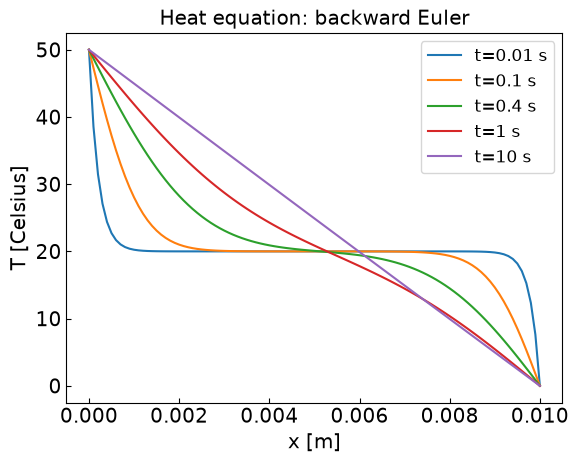

CPU times: user 73 ms, sys: 4.06 ms, total: 77 ms
Wall time: 76 ms


In [12]:
%%time

L = 0.01
D = 4.25e-6
N = 100
a = L / N
h = 1e-2
r = h * D / a**2
print("Solving the heat equation with implicit scheme; r =", r)

u = np.full(N + 1, 20.0)
u[0], u[-1] = 50.0, 0.0
times = [0.01, 0.1, 0.4, 1.0, 10.0]
profiles = []
xk = np.linspace(0, L, N + 1)
current_time = 0.0
for time in times:
    nsteps = round((time - current_time) / h)
    u = heat_implicit_solve(u, h, nsteps, a, D)
    profiles.append(u.copy())
    current_time += nsteps * h

plt.figure()
plt.title("Heat equation: backward Euler")
plt.xlabel("x [m]")
plt.ylabel("T [Celsius]")
for time, profile in zip(times, profiles):
    plt.plot(xk, profile, label=f"t={time:g} s")
plt.legend()
plt.show()


アニメーション

In [13]:
%%time

from matplotlib.animation import FuncAnimation

L = 0.01
D = 4.25e-6
N = 100
a = L / N
h = 1e-3
xk = np.linspace(0, L, N + 1)
u = np.full(N + 1, 20.0)
u[0], u[-1] = 50.0, 0.0
current_time = 0.0
fig, ax = plt.subplots(figsize=(7, 4))
line, = ax.plot(xk, u)
ax.set(xlabel="x [m]", ylabel="T [Celsius]", ylim=(-2, 52))
ax.set_title("Heat equation: backward Euler")

def animate_heat_equation(frame):
    global u, current_time
    nsteps = 20
    u = heat_implicit_solve(u, h, nsteps, a, D)
    current_time += h * nsteps
    line.set_ydata(u)
    ax.set_title(f"Heat equation: t={current_time:.2f} s")
    return (line,)

ani = FuncAnimation(fig, animate_heat_equation, frames=75, interval=40, blit=True)
ani.save("heat_equation_1D_implicit.gif")
plt.close(fig)


MovieWriter ffmpeg unavailable; using Pillow instead.


CPU times: user 3.1 s, sys: 210 ms, total: 3.31 s
Wall time: 3.31 s


## 3. Crank-Nicolson 法

クランク・ニコルソン法は、FTCS法と陰解法を組み合わせたもの。
本質的には、時間微分を陽解法と陰解法の平均として近似することに相当する。
$$
\frac{\partial u(t,x)}{\partial t} \approx \frac{1}{2} \left[ D \, \frac{\partial^2 u(t+h,x)}{\partial x^2} + D \, \frac{\partial^2 u(t,x)}{\partial x^2} \right].
$$

空間微分に中心差分を適用すると、次の式が得られる。
$$
\frac{u(t+h,x) - u(t,x)}{h} = \frac{D}{2} \frac{u(t+h,x+a) - 2u(t+h,x) + u(t+h,x-a)}{a^2} + \frac{D}{2} \frac{u(t,x+a) - 2u(t,x) + u(t,x-a)}{a^2}.
$$

これは次の三重対角線線形方程式系に対応する。
$$
-r u^{n+1}_{k-1} + 2(1+r) u^{n+1}_{k} - r u^{n+1}_{k+1} = ru^n_{k-1} + 2(1-r)u^n_k + ru^n_{k+1}, \qquad k = 1 \ldots N-1.
$$

In [14]:
# 熱方程式Crank-Nicolson法
def heat_crank_nicolson_iteration(u, r):
    n = len(u) - 1
    size = n - 1
    diagonal = np.full(size, 1 + r)
    off = np.full(size - 1, -r / 2)
    rhs = (1 - r) * u[1:n] + (r / 2) * (u[:-2] + u[2:])
    rhs[0] += (r / 2) * u[0]
    rhs[-1] += (r / 2) * u[n]
    unew = u.copy()
    unew[1:n] = linsolve_tridiagonal(diagonal, off, off, rhs)
    return unew

def heat_crank_nicolson_solve(u0, h, nsteps, a, D=1.0):
    u = u0.copy()
    r = h * D / a**2
    for _ in range(nsteps):
        u = heat_crank_nicolson_iteration(u, r)
    return u


Solving the heat equation with Crank-Nicolson; r = 4.25


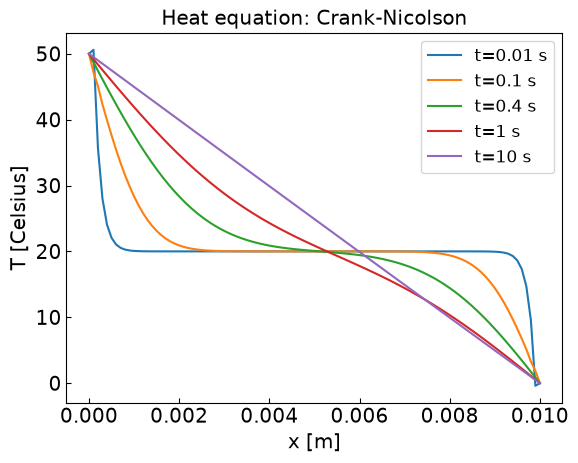

CPU times: user 76.2 ms, sys: 1.07 ms, total: 77.2 ms
Wall time: 76.5 ms


In [15]:
%%time

L = 0.01
D = 4.25e-6
N = 100
a = L / N
h = 1e-2
r = h * D / a**2
print("Solving the heat equation with Crank-Nicolson; r =", r)

u = np.full(N + 1, 20.0)
u[0], u[-1] = 50.0, 0.0
times = [0.01, 0.1, 0.4, 1.0, 10.0]
profiles = []
xk = np.linspace(0, L, N + 1)
current_time = 0.0
for time in times:
    nsteps = round((time - current_time) / h)
    u = heat_crank_nicolson_solve(u, h, nsteps, a, D)
    profiles.append(u.copy())
    current_time += nsteps * h

plt.figure()
plt.title("Heat equation: Crank-Nicolson")
plt.xlabel("x [m]")
plt.ylabel("T [Celsius]")
for time, profile in zip(times, profiles):
    plt.plot(xk, profile, label=f"t={time:g} s")
plt.legend()
plt.show()


# 実習: 1次元波動方程式

1次元の波動方程式をCrank-Nicolson法で解く。二つの初期条件
\(\phi(0,x)\) と \(\partial_t\phi(0,x)\)、および境界条件を与える。

\[
\frac{\partial^2\phi}{\partial t^2}
= v^2\frac{\partial^2\phi}{\partial x^2},
\qquad
\psi=\partial_t\phi.
\]

ここでは固定端のDirichlet境界条件 \(\phi(t,0)=\phi(t,L)=0\) を使う。
FTCS法、陰解法、Crank-Nicolson法の差分式を実装し、安定性とエネルギーを比較する。


Crank-Nicolson法では、時間平均を用いる：
\[
\phi^{n+1}=\phi^n+\frac{h}{2}(\psi^{n+1}+\psi^n),\qquad
\psi^{n+1}=\psi^n+\frac{r}{2}L(\phi^{n+1}+\phi^n),
\]
ここで \(L\phi_k=\phi_{k+1}-2\phi_k+\phi_{k-1}\)、\(r=hv^2/a^2\)。
第1式を代入すると
\[
(4I-rhL)\psi^{n+1}=(4I+rhL)\psi^n+4rL\phi^n.
\]
したがって、内部点では
\[
-rh\psi^{n+1}_{k+1}+(4+2rh)\psi^{n+1}_k-rh\psi^{n+1}_{k-1}
=4\psi^n_k+4rL\phi^n_k+rhL\psi^n_k.
\]
この三重対角方程式を実装し、時刻 t=1, 5, 10, 20, 190, 290 に変位をプロットする。
このセルは実習用の空欄として残す。
